# Fetching the data

The data that is used in the paper is related to various financial instruments:

- GOLD --> Gold futures
- Silver --> Silver futures
- Wheat -->	Wheat futures
- GAZ -->	Natural gas futures
- SP500 -->	S&P 500	
- NSDQ -->	Nasdaq Composite
- VIX -->	Volatility index
- IBEX -->	IBEX 35 (Spain)
- AEX -->	AEX (Netherlands)
- BEL -->	BEL 20 (Belgium)
- DAX -->	DAX (Germany)
- FTSE -->	FTSE 100 (UK)
- SMI -->	Swiss Market Index
- ASX -->	ASX 200 (Australia)
- N225 -->	Nikkei 225
- HIS -->	Hang Seng
- Nifty -->	Nifty 50 (India)
- BVSP -->	Bovespa (Brazil)	
- NZX -->	NZX 50 (New Zealand)
- US yield  -->	US 10-year Treasury

In [80]:
%pip install pandas requests yfinance
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [81]:
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import yfinance as yf
import math

from pathlib import Path
from dataclasses import dataclass
from sklearn.base import BaseEstimator, clone
from sklearn.model_selection import TimeSeriesSplit
from joblib import Parallel, delayed
from sklearn.utils.metaestimators import _safe_split
from typing import Callable
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance


# Data collection

In [82]:
START = "2000-01-01"
END = "2026-01-30" 
PERIOD = '1d'

OUT = Path("data/raw")
OUT.mkdir(parents=True, exist_ok=True)

YAHOO = {
    "gold":   ["GC=F"],
    "silver": ["SI=F"],
    "wheat":  ["ZW=F"],
    "gaz":    ["NG=F"],
    "sp500":  ["^GSPC"],
    "nsdq":   ["^IXIC"],
    "vix":    ["^VIX"],
    "ibex":   ["^IBEX"],
    "aex":    ["^AEX"],
    "bel":    ["^BFX"],
    "dax":    ["^GDAXI"],
    "ftse":   ["^FTSE"],
    "smi":    ["^SSMI"],
    "asx":    ["^AXJO"],
    "n225":   ["^N225"],
    "his":    ["^HSI"],
    "nifty":  ["^NSEI"],
    "bvsp":   ["^BVSP"],
    "nzx":    ["^NZ50"],
    "ta35":   ["TA35.TA"],
    "oil": ["CL=F"]
}

In [83]:
""" Functions to fetch the data"""

def fetch_single_asset(name):
    ticker = YAHOO[name]

    try:
        data = yf.download(
            tickers=ticker,
            interval=PERIOD,
            start=START,
            end=END
        )

        close = data["Close"].iloc[:, 0]
        
        close.name = name
        return close

    except Exception as e:
        print(f"{name}: {e}")
        return None

def fetch_all():

    # Fetch Yahoo data
    dico = {}

    for name in YAHOO.keys():
        result = fetch_single_asset(name)

        if result is not None:
            dico[name] = result

    yahoo_df = pd.concat(dico, axis=1, sort=True)

    # Fetch US yield data
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10"
    r = requests.get(url, timeout=30)
    r.raise_for_status()

    df = pd.read_csv(
        io.StringIO(r.text),
        index_col=0,
        parse_dates=True
    )

    usyield = pd.to_numeric(df.iloc[:, 0], errors="coerce").loc[START:END]
    usyield.name = "us_yield"

    # Combine all data
    data = pd.concat(
        [yahoo_df, usyield],
        axis=1,
        sort=True
    )

    return data

def check_data_validity(data: pd.DataFrame, verbose: bool = True) -> pd.DataFrame:
    if verbose:
        # Check the validity of the timestamps
        if not isinstance(data.index, pd.DatetimeIndex):
            print("The index of the data is not a DatetimeIndex.")
            data.index = pd.to_datetime(data.index, errors="raise")
            print("Solved the problem. The indexes are now datetimes.\n")

        # Check the ordering of observations
        if not data.index.is_monotonic_increasing:
            print("The observations are not properly ordered.")
            data.sort_index(ascending=True, inplace=True)
            print("The observations are now properly ordered.\n")

        # Check for missing values
        missing_cols = data.columns[data.isna().any()]

        if len(missing_cols) > 0:
            print("Missing values detected.")
            data.loc[:, missing_cols] = data.loc[:, missing_cols].ffill()

            remaining_missing = data.columns[data.isna().any()]

            if len(remaining_missing) > 0:
                print("Some missing values remain after forward filling.")
                print(data.isna().sum())
                print("\n")
                print("Check on the indexes")
                print(len(data.index) == len(data.index.unique()))

    return data.dropna()

def build_features(data: pd.DataFrame, lag_order: int = 10, target_col: str = "oil") -> tuple[pd.DataFrame]:

    data = data.copy()

    return_cols = data.columns.tolist()
    predictions_cols = []

    # transform the VIX in a dummy variable
    data["vix_dummy"] = (data["vix"] > 20).astype("int8")
    predictions_cols.append("vix_dummy")

    # transform every columns into returns
    # I did a forward:backward fill so when computing returns, there will be articial zeros in the dataset. We should think about it
    
    data[return_cols] = data[return_cols].pct_change(fill_method=None)

    # compute lag up to order 10 of all the columns
    lag_features = {
        f"{col}_lag_{i}": data[col].shift(i)
        for col in return_cols
        for i in range(1, lag_order+1)
    }
    predictions_cols.extend(lag_features.keys())
    data = pd.concat([data, pd.DataFrame(lag_features, index=data.index)], axis=1)

    # moving_averages on the target_col up order 10. we exclude order 1 since it is equivalent to just seeing lag 1. It would introduce a duplicate column
    ma_features = {
        f"{target_col}_ma{i}": data[target_col].shift(1).rolling(window=i, min_periods=i).mean()
        for i in range(2, lag_order + 1)
    } 
    predictions_cols.extend(ma_features.keys())
    data = pd.concat([data, pd.DataFrame(ma_features, index=data.index)],axis=1)

    prediction_dataset = data[predictions_cols+[target_col]].dropna()
    target = prediction_dataset[target_col]
    features =  prediction_dataset[predictions_cols]

    # Verifications
    assert (np.all(features.index == target.index))
    assert(len(features.index) == features.index.nunique())
    assert(features.isna().any().sum() == 0)
    assert(target.isna().any().sum() == 0)
    assert(np.isfinite(features).all().all() and np.isfinite(target).all().all())
    
    return features, target, data[return_cols]

def prepare_tuning_data(features: pd.DataFrame, target: pd.DataFrame, tuning_end_date: str = "2020-01-01"):

    x = features
    y = target

    data = x.join(y.rename("target"), how="inner").sort_index()
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    x = data.drop(columns="target")
    y = data["target"]
    y_next = y.shift(-1).rename("target_next").dropna() # Features at t predict the return at t+1

    supervised_data = x.join(y_next).dropna()

    tuning_end = tuning_end_date 
    tuning_data = supervised_data.loc[:tuning_end]

    X_tune = tuning_data[x.columns]
    y_tune = tuning_data["target_next"]

    return X_tune, y_tune

In [84]:
"""Backtest class and methods to compute predictions and holdings in portfolio"""

def compute_pnl(
    h: pd.DataFrame | pd.Series,
    ret: pd.DataFrame | pd.Series,
    pred_lag: int = 1,
) -> pd.Series:
    """Compute PnL from holdings and returns.

    Args:
        h: Holdings at each time step.
        ret: Asset returns.
        pred_lag: Number of periods to lag holdings (avoids lookahead).

    Returns:
        PnL series (summed across assets if multi-asset).
    """
    pnl = h.shift(pred_lag).mul(ret)
    if isinstance(h, pd.DataFrame):
        pnl = pnl.sum(axis=1)
    return pnl


def fit_predict(
    estimator: BaseEstimator,
    X: np.ndarray,
    y: np.ndarray,
    train: np.ndarray,
    test: np.ndarray,
    return_estimator: bool = True,
) -> tuple:
    """Fit estimator on train split and predict on test split.

    Args:
        estimator: sklearn-compatible estimator.
        X: Feature matrix.
        y: Target matrix.
        train: Train indices.
        test: Test indices.
        return_estimator: If True, return (predictions, fitted_estimator).

    Returns:
        Predictions, or tuple of (predictions, estimator).
    """
    X_train, y_train = _safe_split(estimator, X, y, train)
    X_test, _ = _safe_split(estimator, X, y, test, train)
    estimator.fit(X_train, y_train)
    if return_estimator:
        return estimator.predict(X_test), estimator
    else:
        return estimator.predict(X_test)

@dataclass
class Backtester:
    """Walk-forward backtester for prediction and portfolio timing."""

    estimator: BaseEstimator | None = None
    max_train_size: int = 36
    test_size: int = 1
    pred_lag: int = 1
    start_date: str = "2022-01-01"
    end_date: str | None = None
    name: str | None = None

    def __post_init__(self):
        if self.estimator is None:
            from sklearn.tree import DecisionTreeRegressor
            self.estimator = DecisionTreeRegressor(
                max_depth=5,
                min_samples_leaf=10,
                random_state=42,
            )

    def compute_predictions(
        self,
        X: pd.DataFrame,
        y: pd.Series | pd.DataFrame,
        n_jobs: int = 1,
    ):
        """Generate out-of-sample predictions with walk-forward validation."""

        common_idx = X.index.intersection(y.index).sort_values()
        X = X.loc[common_idx].sort_index()
        real = y.copy() # temp data to store y
        y = y.loc[X.index].shift(-1).dropna()

        if self.end_date is not None:
            mask = X.index <= pd.Timestamp(self.end_date)
            X, y = X.loc[mask], y.loc[mask]

        n_test = len(X.loc[self.start_date:])
        if n_test == 0:
            raise ValueError("No observations found on or after start_date.")

        n_splits = math.ceil(n_test / self.test_size)
        if n_splits >= len(X):
            raise ValueError("Not enough observations for walk-forward training.")

        cv = TimeSeriesSplit(
            max_train_size=self.max_train_size,
            test_size=self.test_size,
            n_splits=n_splits,
        )

        def fit_predict(train, test):
            model = clone(self.estimator)
            model.fit(X.iloc[train], y.iloc[train])
            return model.predict(X.iloc[test]), model, test

        results = Parallel(n_jobs=n_jobs)(
            delayed(fit_predict)(train, test)
            for train, test in cv.split(X)
        )

        predictions = np.concatenate([r[0] for r in results], axis=0)
        test_indices = np.concatenate([r[2] for r in results])
        pred_idx = X.index[test_indices]

        mask = pred_idx >= pd.Timestamp(self.start_date)
        if self.end_date is not None:
            mask &= pred_idx <= pd.Timestamp(self.end_date)

        predictions = predictions[mask]
        pred_idx = pred_idx[mask]

        if isinstance(y, pd.DataFrame):
            self.predictions_ = pd.DataFrame(
                predictions, index=pred_idx, columns=y.columns
            )
        else:
            self.predictions_ = pd.Series(
                np.asarray(predictions).reshape(-1),
                index=pred_idx,
                name=self.name or "prediction",
            )

        self.actual_ = real.loc[pred_idx]
        self.estimators_ = tuple(r[1] for r in results)
        self.cv_ = cv

        return self

    def compute_holdings(
        self,
        X: pd.DataFrame,
        y: pd.Series | pd.DataFrame,
        n_jobs: int = 1,
    ):
        """Generate out-of-sample portfolio holdings."""
        self.compute_predictions(X, y, n_jobs=n_jobs)

        tmv = TimingMeanVariance(a_min=-0.25, a_max=0.25)
        tmv.fit(None, self.predictions_)
        self.h_ = pd.Series(
            tmv.predict(self.predictions_),
            index=self.predictions_.index
        )

    def compute_pnl(self, ret: pd.DataFrame | pd.Series):
        """Compute PnL from fitted holdings and returns.

        Args:
            ret: Asset returns (same index/columns as y).

        Returns:
            self (with pnl_ fitted attribute).
        """
        pnl = compute_pnl(self.h_, ret, self.pred_lag)
        self.pnl_ = pnl.loc[self.start_date:self.end_date]
        if self.name:
            self.pnl_ = self.pnl_.rename(self.name)
        return self

    def train_rawPredictions(
        self,
        X: pd.DataFrame,
        y: pd.Series | pd.DataFrame,
    ):
        """Return raw model predictions, without portfolio allocation."""
        self.compute_predictions(X, y)
        return self.predictions_

    def train_empirical_results(
        self,
        X: pd.DataFrame,
        y: pd.Series | pd.DataFrame,
        ret: pd.Series | pd.DataFrame,
    ):
        """Run the full walk-forward portfolio backtest."""
        self.compute_holdings(X, y)
        self.compute_pnl(ret)
        return self.pnl_

def plot_result(predictions, actual, asset="Oil"):
    
    plt.figure(figsize=(8, 8))

    plt.scatter(predictions, actual, alpha=0.6)

    # Perfect prediction reference line
    limits = [
        min(np.min(predictions), np.min(actual)),
        max(np.max(predictions), np.max(actual))
    ]
    plt.plot(limits, limits, "r--", label="Perfect predictions")

    plt.xlabel(f"Predicted {asset} returns")
    plt.ylabel(f"Real {asset} returns")
    plt.title(f"Real vs Predicted {asset} Returns")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.axis("equal")
    plt.tight_layout()
    plt.show()

class TimingMeanVariance(BaseEstimator):
    """Single-asset timing estimator that scales positions by inverse volatility."""

    def __init__(
        self,
        transform_V: Callable | None = None,
        a_min: float | None = None,
        a_max: float | None = None,
    ):
        if transform_V is None:
            self.transform_V = lambda x: np.var(x)
        else:
            self.transform_V = transform_V
        self.a_min = a_min
        self.a_max = a_max

    def fit(self, X, y=None):
        self.V_ = self.transform_V(y)
        return self

    def predict(self, X):
        if self.a_min is None and self.a_max is None:
            h = X / self.V_
        else:
            h = np.clip(
                X / np.sqrt(self.V_), a_min=self.a_min, a_max=self.a_max
            ) / np.sqrt(self.V_)
        return h

    def transform(self, X):
        """Alias for predict (enables sklearn pipeline use)."""
        return self.predict(X)

def hyperparameter_optimization(features: pd.DataFrame, 
                                target: pd.Series | pd.DataFrame, 
                                models_and_params: dict, 
                                n_splits: int = 5,
                                max_train_size: int = 120,
                                test_size: int = 30):
    
    cv = TimeSeriesSplit(
        n_splits=5,
        max_train_size=120,
        test_size=30,
    )

    best_models = {}

    for name, (model, param_grid) in models_and_params.items():
        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_grid,
            n_iter=25,
            scoring="neg_root_mean_squared_error",
            cv=cv,
            random_state=13112026,
            n_jobs=-1,
            refit=True,
            error_score="raise",
        )

        search.fit(features, target)

        best_models[name] = search.best_estimator_

        print(f"\n{name}")
        print("Best parameters:", search.best_params_)
        print("CV RMSE:", round(-search.best_score_, 6))

    return best_models


def features_selector(X_tune: pd.DataFrame, y_tune: pd.DataFrame, n_features: int = 100, show_features: bool = False):

    cv = TimeSeriesSplit(n_splits=5)
    fold_importances = []

    for train_idx, val_idx in cv.split(X_tune):
        selector = RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=10,
            max_features=0.5,
            random_state=13112026,
            n_jobs=-1,
        )

        selector.fit(X_tune.iloc[train_idx], y_tune.iloc[train_idx])

        importance = permutation_importance(
            selector,
            X_tune.iloc[val_idx],
            y_tune.iloc[val_idx],
            scoring="neg_root_mean_squared_error",
            n_repeats=5,
            random_state=13112026,
            n_jobs=-1,
        )

        fold_importances.append(
            pd.Series(importance.importances_mean, index=X_tune.columns)
        )

    importance_scores = (
        pd.concat(fold_importances, axis=1)
        .mean(axis=1)
        .sort_values(ascending=False)
    )

    if show_features:
        display(importance_scores.head(n_features).to_frame("Importance"))

    return importance_scores.head(n_features).index.to_list()

In [85]:
"""Performance and risk metrics."""

def _test_monthly(df: pd.Series) -> bool:
    """Check if the series has monthly frequency."""
    return int(len(df) / len(df.asfreq("ME"))) == 1


def _test_bday(df: pd.Series) -> bool:
    """Check if the series has business-day frequency."""
    return int(len(df) / len(df.asfreq("B"))) == 1


def _test_day(df: pd.Series) -> bool:
    """Check if the series has calendar-day frequency."""
    return int(len(df) / len(df.asfreq("D"))) == 1


def sharpe_ratio(
    df: pd.Series,
    num_period_per_year: int | None = None,
    remove_zeros: bool = True,
) -> float:
    """Compute annualized Sharpe ratio.

    Args:
        df: PnL or returns series with a DatetimeIndex.
        num_period_per_year: Annualization factor. Auto-detected from index if None.
        remove_zeros: Replace zeros with NaN before computing (avoids deflating vol).

    Returns:
        Annualized Sharpe ratio, or NaN if frequency cannot be detected.
    """
    if num_period_per_year is None:
        if _test_monthly(df):
            num_period_per_year = 12
        if _test_bday(df):
            num_period_per_year = 260
        if _test_day(df):
            num_period_per_year = 365
        if num_period_per_year is None:
            return np.nan
    if remove_zeros:
        df = df.replace(0, np.nan)
    return df.mean() / df.std() * np.sqrt(num_period_per_year)


def drawdown(
    x: pd.Series,
    return_in_risk_unit: bool = True,
    window: int = 36,
    num_period_per_year: int = 252,
) -> pd.Series:
    
    """Compute drawdown from peak cumulative PnL.

    Args:
        x: PnL or returns series.
        return_in_risk_unit: Normalize by rolling volatility for cross-strategy comparison.
        window: Rolling window for volatility estimate (in periods).
        num_period_per_year: Annualization factor for the volatility normalization.

    Returns:
        Drawdown series (non-positive values; 0 at peaks).
    """
    dd = x.cumsum().sub(x.cumsum().cummax())
    if return_in_risk_unit:
        return dd.div(x.rolling(window).std().mul(np.sqrt(num_period_per_year)))
    return dd

In [86]:
"""Visualization helpers for quick data exploration."""

def set_axis(
    ax: plt.Axes | None = None,
    figsize: tuple = (8, 5),
    title: str | None = None,
    fig: plt.Figure | None = None,
) -> tuple[plt.Figure, plt.Axes]:
    """Create or reuse a matplotlib figure and axes pair.

    Args:
        ax: Existing axes to reuse. If None, creates a new figure.
        figsize: Figure size as (width, height) in inches.
        title: Optional title for the axes.
        fig: Existing figure to associate with the axes.

    Returns:
        Tuple of (figure, axes).
    """
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=figsize)
    else:
        fig = fig or ax.get_figure()
    if title is not None:
        ax.set_title(title)
    return fig, ax


def line(
    df: pd.DataFrame | pd.Series | dict | list,
    sort: bool = True,
    figsize: tuple = (8, 5),
    ax: plt.Axes | None = None,
    title: str = "",
    cumsum: bool = False,
    loc: str = "center left",
    bbox_to_anchor: tuple | None = (1, 0.5),
    legend_sharpe_ratio: bool | None = None,
    legend: bool = True,
    yscale: str | None = None,
    start_date: str | None = None,
    num_period_per_year: int = 252
):
    """Plot one or more time series as lines.

    Args:
        df: Data to plot. Accepts DataFrame, Series, dict, or list of Series.
        sort: Sort columns by final value (highest on top).
        figsize: Figure size as (width, height) in inches.
        ax: Existing axes to plot on.
        title: Plot title.
        cumsum: Cumulate the series before plotting.
        loc: Legend location string.
        bbox_to_anchor: Legend anchor point.
        legend_sharpe_ratio: Append Sharpe ratio to legend labels. Auto-enabled with cumsum.
        legend: Whether to show the legend.
        yscale: Y-axis scale (e.g. "log").
        start_date: Trim data before this date.
    """
    df = df.copy() if isinstance(df, (pd.DataFrame, pd.Series)) else df
    if loc == "best":
        bbox_to_anchor = None
    if isinstance(df, (dict, list)):
        df = pd.concat(df, axis=1)
    if isinstance(df, pd.Series):
        df = df.to_frame()
    if start_date is not None:
        df = df[start_date:]
    if cumsum and legend_sharpe_ratio is None:
        legend_sharpe_ratio = True
    if legend_sharpe_ratio:
        df.columns = [f"{c}: sr={sharpe_ratio(df[c], num_period_per_year=num_period_per_year): 3.2f}" for c in df.columns]
    if cumsum:
        df = df.cumsum()
    if sort:
        df = df.loc[:, lambda x: x.iloc[-1].sort_values(ascending=False).index]
    if ax is None:
        fig, ax = set_axis(ax=ax, figsize=figsize)
    ax.set_axisbelow(True)
    ax.grid(True, linestyle="--", alpha=0.5)
    if title != "":
        ax.set_title(title)
    ax.plot(df.index, df.values)
    if legend:
        ax.legend(df.columns, loc=loc, bbox_to_anchor=bbox_to_anchor)
    if yscale == "log":
        ax.set_yscale("log")

def display_results(features: pd.DataFrame, target: pd.DataFrame, 
                    best_models: dict, start_date: str = "2019-01-01", asset="Oil", 
                    show_metrics: bool = False):

    results = {}
    prediction_metrics = {}
    pnl_series = {}
    drawdown_series = {}
    
    X = features
    y = target
    y_next = y.shift(-1).rename("target_next").dropna()

    for name, best_model in best_models.items():

        bt = Backtester(
            estimator=clone(best_model),
            max_train_size=100,
            test_size=10,
            pred_lag=1,
            start_date=start_date,
            name=name,
        )

        bt.compute_predictions(X, y_next)

        pred = bt.predictions_
        actual = bt.actual_

        prediction_metrics[name] = {
            "RMSE": mean_squared_error(actual, pred) ** 0.5,
            "MAE": mean_absolute_error(actual, pred),
            "R2": r2_score(actual, pred) if len(actual) > 1 else np.nan,
        }

        bt.compute_holdings(X, y)
        bt.compute_pnl(y)

        pnl = bt.pnl_.dropna()
        pnl_series[name] = pnl
        
        dd = drawdown(pnl,return_in_risk_unit=True)
        drawdown_series[name] = dd

        results[name] = {
            "PnL cumulé": pnl.sum(),
            "Sharpe": sharpe_ratio(pnl,num_period_per_year=252),
            "Max drawdown": dd.min(),
        }

    pnl = pd.DataFrame(pnl_series)
    dd = pd.DataFrame(drawdown_series)

    line(pnl,cumsum=True,title=f"Cumulated PnL for {asset}",start_date=start_date,loc="best")
    line(dd,cumsum=True,title=f"Drawdown for {asset}",start_date=start_date,legend_sharpe_ratio=False,loc="best")

    if show_metrics:

        prediction_table = pd.DataFrame(prediction_metrics).T
        performance_table = pd.DataFrame(results).T

        print("Out of sample Performance")
        display(prediction_table.round(4))

        print("Financial performance")
        display(performance_table.round(4))


# Full Analysis

In [87]:
allData = fetch_all()
cleaned_data = check_data_validity(allData, verbose=False)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%********

In [88]:
features_oil, target_oil, _ = build_features(cleaned_data, lag_order=10, target_col="oil")
features_gold, target_gold, _ = build_features(cleaned_data, lag_order=10, target_col="gold")

In [89]:
models_and_params = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=13112026),
        {
            "max_depth": [2, 3, 5, 8],
            "min_samples_leaf": [5, 10, 20, 30],
            "max_features": [1.0, 0.5, "sqrt"],
        },
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=13112026, n_jobs=1),
        {
            #"n_estimators": [100, 200, 400],
            "max_depth": [3, 5, 8],
            "min_samples_leaf": [5, 10, 20, 30],
            "max_features": [1.0, 0.5, "sqrt"],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=13112026),
        {
            "n_estimators": [50, 100, 200, 300],
            "learning_rate": [0.01, 0.03, 0.05, 0.1],
            "max_depth": [1, 2, 3, 5, 8],
            "min_samples_leaf": [5, 10, 20, 30],
            #"subsample": [0.7, 0.9, 1.0],
        },
    ),
}

TUNING_END_DATE = "2015-12-31"
PREDICTION_START_DATE = "2016-01-01"

X_tune_oil, y_tune_oil = prepare_tuning_data(features=features_oil, target=target_oil, tuning_end_date=TUNING_END_DATE)
X_tune_gold, y_tune_gold = prepare_tuning_data(features=features_gold, target=target_gold, tuning_end_date=TUNING_END_DATE)

In [90]:
best_models_oil = hyperparameter_optimization(features=X_tune_oil, target=y_tune_oil, models_and_params=models_and_params)
best_models_gold = hyperparameter_optimization(features=X_tune_gold, target=y_tune_gold, models_and_params=models_and_params)


Decision Tree
Best parameters: {'min_samples_leaf': 30, 'max_features': 0.5, 'max_depth': 2}
CV RMSE: 0.037747

Random Forest
Best parameters: {'min_samples_leaf': 30, 'max_features': 'sqrt', 'max_depth': 8}
CV RMSE: 0.036235

Gradient Boosting
Best parameters: {'n_estimators': 50, 'min_samples_leaf': 20, 'max_depth': 2, 'learning_rate': 0.05}
CV RMSE: 0.03689

Decision Tree
Best parameters: {'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 2}
CV RMSE: 0.012865

Random Forest
Best parameters: {'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 3}
CV RMSE: 0.012029

Gradient Boosting
Best parameters: {'n_estimators': 50, 'min_samples_leaf': 10, 'max_depth': 2, 'learning_rate': 0.01}
CV RMSE: 0.0122


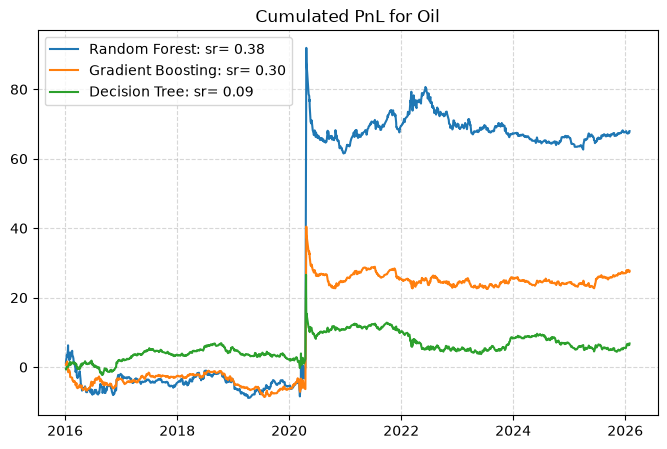

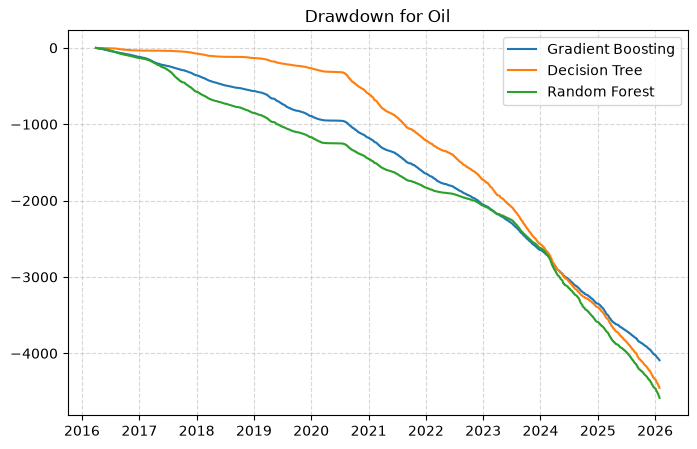

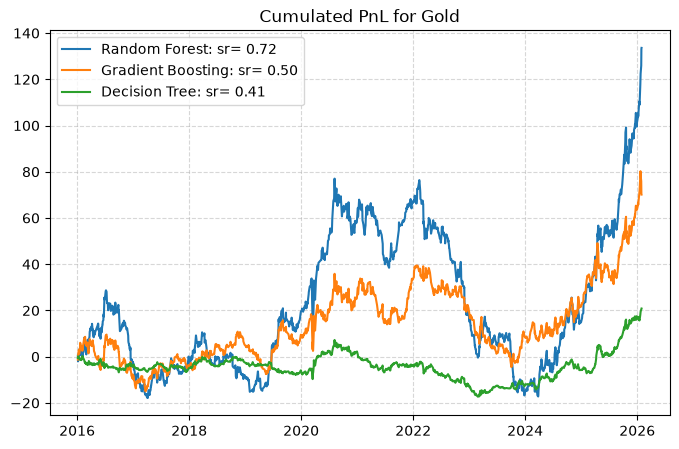

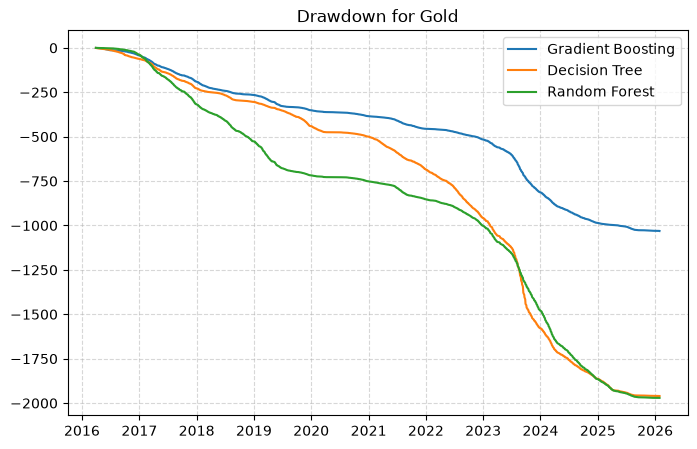

In [93]:
display_results(features=features_oil, target=target_oil, best_models=best_models_oil, start_date=PREDICTION_START_DATE)
display_results(features=features_gold, target=target_gold, best_models=best_models_gold, start_date=PREDICTION_START_DATE, asset="Gold")

# Variables selection

# By Random Forest Feature Importance

In [94]:
selected_features_oil = features_selector(X_tune=X_tune_oil, y_tune=y_tune_oil, n_features=100)
selected_features_gold = features_selector(X_tune=X_tune_gold, y_tune=y_tune_gold, n_features=100)

In [96]:
reduced_features_oil = features_oil[selected_features_oil]
reduced_features_gold = features_gold[selected_features_gold]

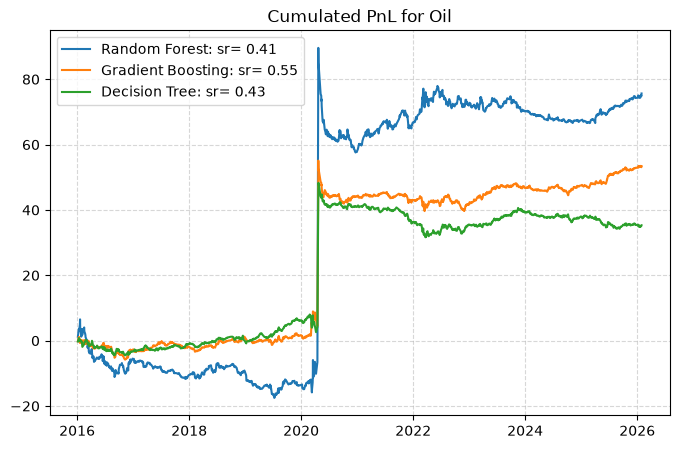

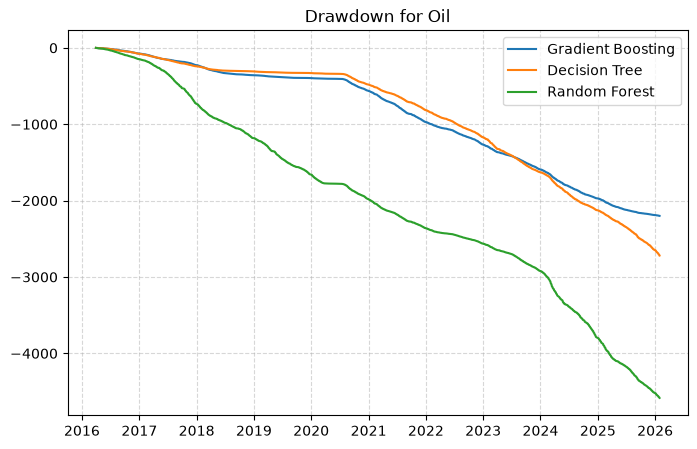

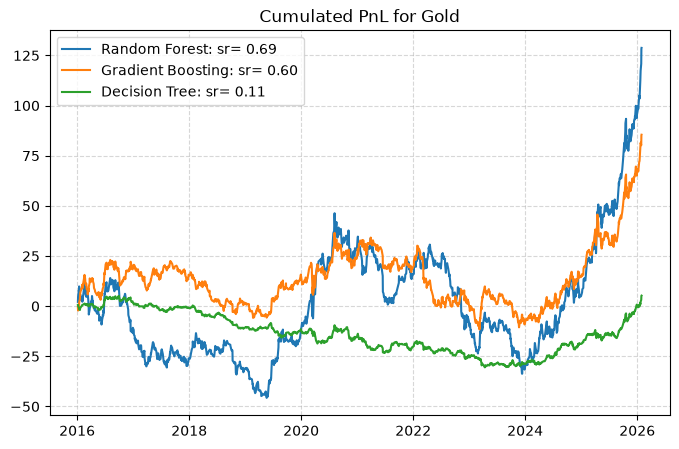

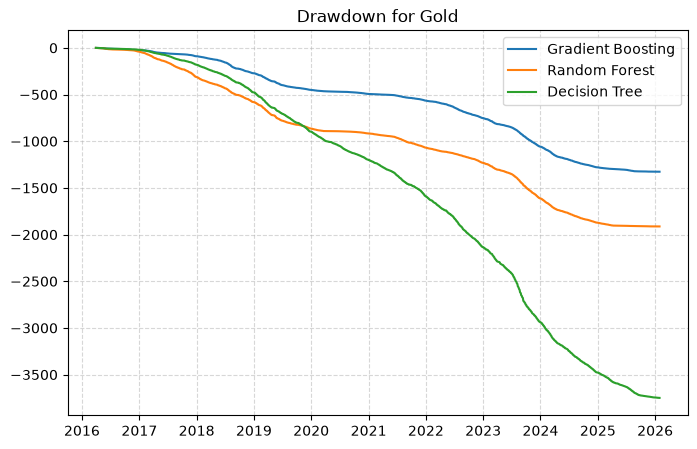

In [97]:
display_results(features=reduced_features_oil, target=target_oil, best_models=best_models_oil, start_date=PREDICTION_START_DATE)
display_results(features=reduced_features_gold, target=target_gold, best_models=best_models_gold, start_date=PREDICTION_START_DATE, asset="Gold")

# By Feature persistence via LASSO regression